# BrushCue Example: Color Halftone

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/color_halftone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/color-halftone

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


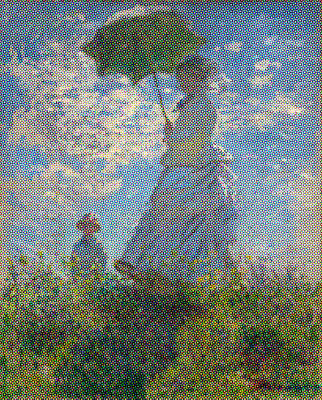

In [1]:
import io
from PIL import Image

import brushcue as bc

dot_size = 12.0
screen_angle = 0.0
input_image = bc.Composition.monet_women_with_parasol()
input_bounds = input_image.bounds()
graph = input_image.spacial_effect_shader(
    "let lo = image_bounds.xy + vec2<f32>(0.5);\nlet hi = image_bounds.zw - vec2<f32>(0.5);\nlet origin = image_bounds.xy;\nlet base_angle = screen_angle * 0.017453293;\nlet c = screen_coverage(position, base_angle + 0.2617994, dot_size, 0, lo, hi, origin);\nlet m = screen_coverage(position, base_angle + 1.3089969, dot_size, 1, lo, hi, origin);\nlet y = screen_coverage(position, base_angle, dot_size, 2, lo, hi, origin);\nlet k = screen_coverage(position, base_angle + 0.7853982, dot_size, 3, lo, hi, origin);\nlet rgb = (vec3<f32>(1.0) - vec3<f32>(c, m, y)) * (1.0 - k);\nlet alpha = sample(clamp(position, lo, hi)).a;\nreturn vec4<f32>(rgb, alpha);",
    "fn rotate2(p: vec2<f32>, a: f32) -> vec2<f32> {\n    let c = cos(a);\n    let s = sin(a);\n    return vec2<f32>(c * p.x - s * p.y, s * p.x + c * p.y);\n}\n\nfn cmyk_of(rgb: vec3<f32>) -> vec4<f32> {\n    let c = clamp(rgb, vec3<f32>(0.0), vec3<f32>(1.0));\n    let k = 0.5 * (1.0 - max(c.r, max(c.g, c.b)));\n    let denom = max(1.0 - k, 0.0001);\n    let cmy = (vec3<f32>(1.0) - c - vec3<f32>(k)) / denom;\n    return vec4<f32>(cmy, k);\n}\n\nfn channel_value(v: vec4<f32>, channel: i32) -> f32 {\n    if (channel == 0) { return v.x; }\n    if (channel == 1) { return v.y; }\n    if (channel == 2) { return v.z; }\n    return v.w;\n}\n\nfn screen_coverage(p: vec2<f32>, angle: f32, cell: f32, channel: i32, lo: vec2<f32>, hi: vec2<f32>, origin: vec2<f32>) -> f32 {\n    let q = rotate2(p - origin, -angle);\n    let base = floor(q / cell);\n    var coverage = 0.0;\n    for (var dy = -1; dy <= 1; dy = dy + 1) {\n        for (var dx = -1; dx <= 1; dx = dx + 1) {\n            let cell_center_q = (base + vec2<f32>(f32(dx), f32(dy)) + vec2<f32>(0.5)) * cell;\n            let cell_center = rotate2(cell_center_q, angle) + origin;\n            let color = sample(clamp(cell_center, lo, hi));\n            let ink = channel_value(cmyk_of(color.rgb), channel) * color.a;\n            let radius = cell * sqrt(ink / 3.14159265);\n            let d = length(q - cell_center_q);\n            coverage = max(coverage, 1.0 - smoothstep(radius - 0.75, radius + 0.75, d));\n        }\n    }\n    return coverage;\n}",
    (dot_size * 3.0),
    bc.Dictionary.create()
    .add("dot_size", dot_size)
    .add("screen_angle", screen_angle)
    .add("image_bounds", input_bounds),
    bc.ColorRepresentation.srgb(),
).crop(input_bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
